# 🤖 Dolandırıcılık (Fraud) Tespiti — Modelleme

Bu notebook, EDA notebook'unun ürettiği `islenmis_veri/train.csv` ve `test.csv` dosyalarını kullanır.

**Sıra:** Sızıntı kontrolü → "Lazy" model yarışı (20+ model) → Dengesizlik stratejileri → Çapraz doğrulama →
Isolation Forest (denetimsiz) → Hiperparametre ayarı → Overfit/Underfit kontrolü → Eşik seçimi → **Test (tek seferlik)**

### 🔒 Bu notebook'un altın kuralları
1. **Test seti sadece en sonda, bir kez** kullanılır. Model seçimi, ayar ve eşik hep **train içinde** yapılır.
2. Dengesizlik düzeltmesi (class_weight / SMOTE / undersampling) **sadece eğitim katlarına** uygulanır, doğrulama ve teste asla.
3. Başarı ölçüsü **Accuracy değil**: PR-AUC, Recall, Precision, F1 ve karışıklık matrisi.
4. Her modelde **train skoru ile doğrulama skoru arasındaki fark** (gap) ölçülür: fark büyükse **overfit**, ikisi de düşükse **underfit**.

> Kurulum gerekmez: sadece `scikit-learn` yeterli. `xgboost`, `lightgbm`, `imbalanced-learn` yüklüyse otomatik kullanılır, yoksa atlanır.

## 0. Kurulum ve Ayarlar
Aşağıdaki değerleri değiştirebilirsin. Hızlı deneme için `HIZLI_MOD = True` yap (daha az katman, daha az arama).

In [1]:
import os, json, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (StratifiedKFold, train_test_split, ParameterSampler,
                                     learning_curve, validation_curve)
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score, accuracy_score, balanced_accuracy_score,
                             matthews_corrcoef, confusion_matrix)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

warnings.filterwarnings("ignore")

# ---------- ✏️ SENİN AYARLARIN ----------
TRAIN_CSV = "islenmis_veri/train.csv"
TEST_CSV  = "islenmis_veri/test.csv"
TARGET    = "Fraud_Label"          # hedef sütun adı (bulunamazsa son sütun alınır)
RANDOM_STATE = 42
HIZLI_MOD = False                  # True: hızlı deneme (3 katman, az arama)
N_JOBS = -1                        # hata alırsan 1 yap
N_SPLITS = 5                       # StratifiedKFold kat sayısı
LAZY_SAMPLE = 20000                # lazy yarış için en fazla kaç eğitim satırı
N_ITER = 12                        # hiperparametre aramasında denenecek kombinasyon
SUPHELI_AUC = 0.90                 # tek başına bu AUC'yi geçen özellik şüpheli sayılır
OZELLIK_SENARYOSU = "tum"          # "tum" | "supheli_cikar" | "otomatik" (şüpheli varsa çıkar)
EKSTRA_CIKAR = []                  # elle çıkarmak istediğin özellikler
GAP_ESIGI = 0.05                   # train-val PR-AUC farkı bunu geçerse "overfit" say
THRESHOLD_STRATEJISI = "f1"        # "f1" (F1'i maksimize et) | "recall" (HEDEF_RECALL'ı sağla)
HEDEF_RECALL = 0.90
# ----------------------------------------

if HIZLI_MOD:
    N_SPLITS, N_ITER, LAZY_SAMPLE = 3, 5, 8000
RS = RANDOM_STATE

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 5), "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
PAL = {0: "#2a9d8f", 1: "#e63946"}

# İsteğe bağlı kütüphaneler: yüklü değilse (veya Windows engellerse) sessizce atla
try:
    from xgboost import XGBClassifier; XGB_OK = True
except Exception as e:
    XGB_OK = False; print("ℹ️ xgboost kullanılamıyor, atlanacak:", str(e)[:80])
try:
    from lightgbm import LGBMClassifier; LGBM_OK = True
except Exception as e:
    LGBM_OK = False; print("ℹ️ lightgbm kullanılamıyor, atlanacak:", str(e)[:80])
try:
    from imblearn.over_sampling import SMOTE; SMOTE_OK = True
except Exception as e:
    SMOTE_OK = False; print("ℹ️ imbalanced-learn yok, SMOTE atlanacak (class_weight ve undersampling yine çalışır)")
print(f"XGBoost: {XGB_OK} | LightGBM: {LGBM_OK} | SMOTE: {SMOTE_OK}")

ℹ️ imbalanced-learn yok, SMOTE atlanacak (class_weight ve undersampling yine çalışır)
XGBoost: True | LightGBM: True | SMOTE: False


## 1. Veriyi Yükleme
EDA notebook'unun kaydettiği **train** ve **test** dosyaları. Test setini şimdilik **sadece boyutuna bakıp kenara koyuyoruz**.

In [2]:
if not (os.path.exists(TRAIN_CSV) and os.path.exists(TEST_CSV)):
    raise FileNotFoundError("islenmis_veri/train.csv bulunamadı. Önce EDA notebook'unu (fraud_detection_eda.ipynb) Run All Cells ile çalıştır.")

tr = pd.read_csv(TRAIN_CSV)
te = pd.read_csv(TEST_CSV)
if TARGET not in tr.columns:
    TARGET = tr.columns[-1]
    print(f"⚠️ Hedef sütun bulunamadı, son sütun kullanıldı: {TARGET}")

X_train, y_train = tr.drop(columns=[TARGET]), tr[TARGET].astype(int)
X_test,  y_test  = te.drop(columns=[TARGET]), te[TARGET].astype(int)
TUM_OZELLIKLER = X_train.columns.tolist()

fraud_orani = y_train.mean()
print(f"Train: {X_train.shape} | Test: {X_test.shape} | Özellik sayısı: {len(TUM_OZELLIKLER)}")
print(f"Fraud oranı → train: %{fraud_orani*100:.2f} | test: %{y_test.mean()*100:.2f}")
print(f"Dengesizlik: 1 fraud'a karşı {(1-fraud_orani)/fraud_orani:.1f} normal")
print(f"\n'Hep normal de' diyen aptal modelin accuracy'si: %{(1-y_test.mean())*100:.1f}  ← bu yüzden accuracy'ye bakmıyoruz")
print(f"Rastgele tahminin PR-AUC'si (taban çizgi) ≈ fraud oranı = {fraud_orani:.3f}")

Train: (40000, 20) | Test: (10000, 20) | Özellik sayısı: 20
Fraud oranı → train: %32.14 | test: %32.13
Dengesizlik: 1 fraud'a karşı 2.1 normal

'Hep normal de' diyen aptal modelin accuracy'si: %67.9  ← bu yüzden accuracy'ye bakmıyoruz
Rastgele tahminin PR-AUC'si (taban çizgi) ≈ fraud oranı = 0.321


## 2. Yardımcı Fonksiyonlar (metrikler, dengesizlik stratejileri, çapraz doğrulama)

**Metrikler**
- **PR-AUC (Average Precision):** Precision-Recall eğrisinin altındaki alan. Dengesiz veride en dürüst özet skor. Taban çizgisi = fraud oranı.
- **Recall:** Gerçek fraud'ların kaçını yakaladık? (Kaçan fraud = banka zararı)
- **Precision:** "Fraud" dediklerimizin kaçı gerçekten fraud? (Yanlış alarm = müşteri sinirlenir)
- **F1:** Precision ve Recall'ın dengesi. **MCC:** dört hücrenin hepsini kullanan dengeli bir skor.

**Dengesizlik stratejileri** (hepsi *sadece eğitim katına* uygulanır)
| Strateji | Ne yapar? |
|---|---|
| `agirlik_yok` | Hiçbir şey yapmaz (karşılaştırma için) |
| `class_weight` | Fraud hatalarını daha pahalı yapar (`balanced`) |
| `undersample` | Çoğunluk sınıfından rastgele örnek atar |
| `SMOTE` | Azınlık sınıfa yapay örnekler üretir |

**Çapraz doğrulama:** `StratifiedKFold` ile her katmanda fraud oranı aynı kalır. Her katta **hem train hem doğrulama PR-AUC'si** ölçülür → farkı = overfit göstergesi.

In [3]:
def skor(m, X):
    """Modelin 'fraud olasılığı / skoru' (sıralama metrikleri için)."""
    if hasattr(m, "predict_proba"):
        return m.predict_proba(X)[:, 1]
    if hasattr(m, "decision_function"):
        return m.decision_function(X)
    return m.predict(X).astype(float)


def metrikler(y, s, esik=None):
    """PR-AUC / ROC-AUC (sıralama) + eşik varsa Precision/Recall/F1/MCC."""
    d = {"PR_AUC": average_precision_score(y, s), "ROC_AUC": roc_auc_score(y, s)}
    if esik is not None:
        yh = (s >= esik).astype(int)
        d.update({"Precision": precision_score(y, yh, zero_division=0), "Recall": recall_score(y, yh),
                  "F1": f1_score(y, yh), "MCC": matthews_corrcoef(y, yh),
                  "Bal_Acc": balanced_accuracy_score(y, yh)})
    return d


def ayarla_agirlik(m, y):
    """Modelde class_weight / scale_pos_weight varsa dengeleme ayarını uygular."""
    m = clone(m); p = m.get_params()
    if "class_weight" in p:
        m.set_params(class_weight="balanced")
    elif "scale_pos_weight" in p:
        m.set_params(scale_pos_weight=float((y == 0).sum() / max((y == 1).sum(), 1)))
    return m


def rastgele_azalt(X, y, seed=RS):
    """Undersampling: çoğunluk sınıfını azınlık sayısına indirir."""
    rng = np.random.RandomState(seed)
    az = y[y == 1].index; cok = y[y == 0].index
    n = min(len(az), len(cok))
    secim = np.concatenate([rng.choice(az, n, replace=False), rng.choice(cok, n, replace=False)])
    return X.loc[secim], y.loc[secim]


def smote_uygula(X, y, seed=RS):
    Xr, yr = SMOTE(random_state=seed).fit_resample(X, y)
    return pd.DataFrame(Xr, columns=X.columns), pd.Series(yr)


STRATEJILER = ["agirlik_yok", "class_weight", "undersample"] + (["SMOTE"] if SMOTE_OK else [])


def cv_degerlendir(model, X, y, strateji="class_weight", n_splits=None, seed=RS):
    """
    StratifiedKFold ile değerlendirir. Dengeleme SADECE eğitim katına uygulanır.
    Döner: oof (doğrulama katlarındaki skorlar), train_ap, val_ap, gap...
    """
    n_splits = n_splits or N_SPLITS
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(len(y)); tr_ap, va_ap = [], []
    X = X.reset_index(drop=True); y = y.reset_index(drop=True)
    for tr_i, va_i in skf.split(X, y):
        Xt, yt, Xv, yv = X.iloc[tr_i], y.iloc[tr_i], X.iloc[va_i], y.iloc[va_i]
        m = clone(model)
        Xf, yf = Xt, yt
        if strateji == "class_weight":
            m = ayarla_agirlik(m, yt)
        elif strateji == "undersample":
            Xf, yf = rastgele_azalt(Xt, yt, seed)
        elif strateji == "SMOTE":
            Xf, yf = smote_uygula(Xt, yt, seed)
        m.fit(Xf, yf)
        oof[va_i] = skor(m, Xv)
        va_ap.append(average_precision_score(yv, oof[va_i]))
        tr_ap.append(average_precision_score(yt, skor(m, Xt)))   # ORİJİNAL eğitim katı üzerinde (yapay örnekler hariç)
    return {"oof": oof, "train_ap": float(np.mean(tr_ap)), "val_ap": float(np.mean(va_ap)),
            "val_std": float(np.std(va_ap)), "gap": float(np.mean(tr_ap) - np.mean(va_ap))}


def yeni_model(ad):
    """Aday model fabrikası (her seferinde taze nesne)."""
    f = {
        "LogisticRegression": lambda: LogisticRegression(max_iter=2000),
        "RandomForest": lambda: RandomForestClassifier(n_estimators=200, n_jobs=N_JOBS, random_state=RS),
        "HistGradientBoosting": lambda: HistGradientBoostingClassifier(random_state=RS),
    }
    if XGB_OK:
        f["XGBoost"] = lambda: XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=5, eval_metric="logloss",
                                              tree_method="hist", n_jobs=N_JOBS, random_state=RS, verbosity=0)
    if LGBM_OK:
        f["LightGBM"] = lambda: LGBMClassifier(n_estimators=300, learning_rate=0.1, n_jobs=N_JOBS, random_state=RS, verbose=-1)
    return f[ad]()


print("Yardımcı fonksiyonlar hazır. Stratejiler:", STRATEJILER)

Yardımcı fonksiyonlar hazır. Stratejiler: ['agirlik_yok', 'class_weight', 'undersample']


## 3. 🚨 Sızıntı Kontrolü: "Çok iyi skor" bazen kötü haberdir

Bir özellik fraud'u **tek başına** neredeyse mükemmel ayırıyorsa (AUC ≈ 1.0), modeller %99-100 skor alır ama bunun sebebi
modelin zekâsı değil, **etiketin o özellikten kural olarak üretilmiş olmasıdır** (sentetik veri setlerinde çok görülür) ya da özelliğin
fraud'dan *sonra* oluşmasıdır. Gerçek hayatta bu model işe yaramaz.

Burada:
1. Her özelliğin **tek başına AUC**'sini hesaplıyorum (sadece train üzerinde). AUC > `SUPHELI_AUC` olanlar şüpheli.
2. **Basit kural testi:** 3 seviyeli minicik bir karar ağacı fraud'u %95+ ayırabiliyorsa etiket muhtemelen birkaç kuraldan üretilmiştir
   (örn. "şu özellik ≥ 4 **veya** şu skor > 0.85"). Hiçbir özellik tek başına şüpheli görünmese bile bu test yakalar. Ağacın kullandığı özellikler şüpheli sayılır.
3. Şüphelilerden türemiş (|korelasyon| > 0.5, örn. oran özellikleri) özellikleri de işaretliyorum; aynı bilgiyi başka kılıkta taşıyorlar.
4. Modelleri **iki senaryoda** karşılaştırıyorum: *A) tüm özellikler* vs *B) şüpheliler çıkarılmış*. İkisini de raporlayabilirsin.

> Varsayılan senaryo `"tum"` (A). Şüpheli özellikler varsa notebook seni uyarır. Dürüst skor için `OZELLIK_SENARYOSU = "supheli_cikar"` yapıp tekrar çalıştır.

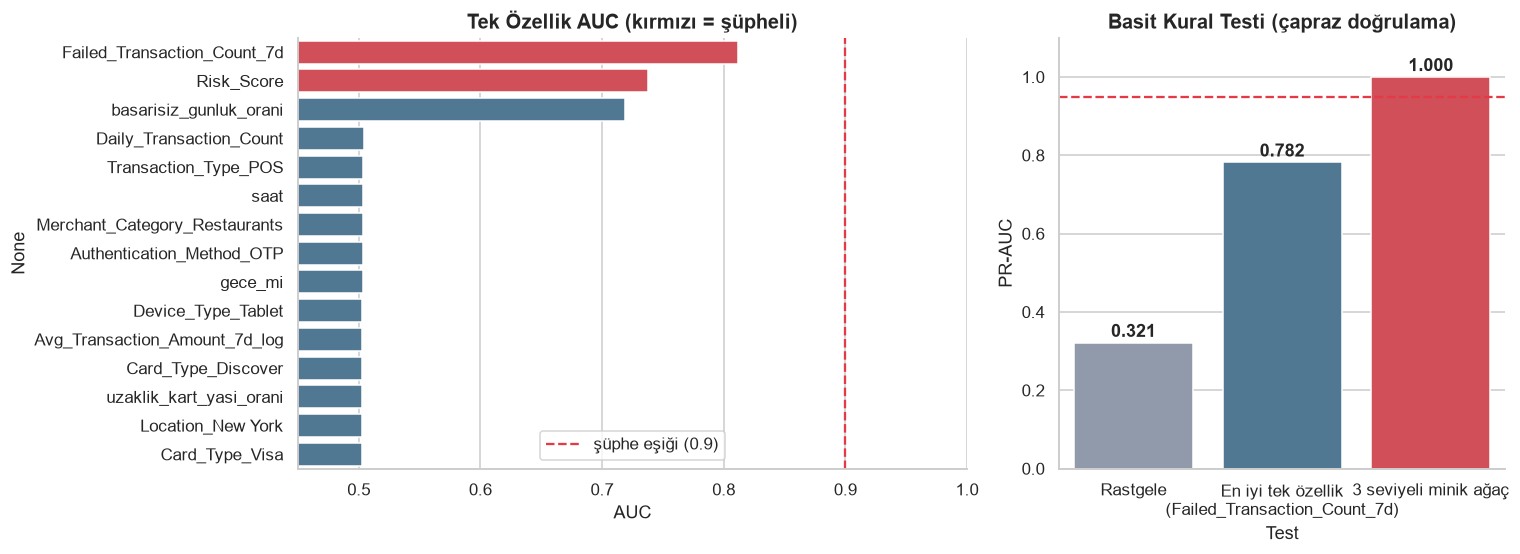

🚨 3 seviyeli minicik bir ağaç fraud'u PR-AUC=1.000 ile ayırıyor. Etiket büyük ihtimalle birkaç basit kuraldan üretilmiş!
   Ağacın bulduğu kural:

|--- Failed_Transaction_Count_7d <= 1.06
|   |--- Risk_Score <= 1.21
|   |   |--- class: 0
|   |--- Risk_Score >  1.21
|   |   |--- class: 1
|--- Failed_Transaction_Count_7d >  1.06
|   |--- class: 1

Şüpheli özellikler: ['Failed_Transaction_Count_7d', 'Risk_Score']
Onlardan türeyen / yüksek korelasyonlu: ['basarisiz_gunluk_orani']
Çıkarılacaklar (senaryo B): ['Failed_Transaction_Count_7d', 'Risk_Score', 'basarisiz_gunluk_orani']


In [4]:
from sklearn.tree import DecisionTreeClassifier, export_text

# 1) Tek özellik AUC'si (sadece train)
auc_tek = {}
for c in TUM_OZELLIKLER:
    if X_train[c].nunique() > 1:
        a = roc_auc_score(y_train, X_train[c]); auc_tek[c] = max(a, 1 - a)
auc_tek = pd.Series(auc_tek).sort_values(ascending=False)
supheli = auc_tek[auc_tek > SUPHELI_AUC].index.tolist()

# 2) Basit kural testi: 3 seviyeli minicik bir karar ağacı fraud'u neredeyse mükemmel ayırabiliyor mu?
#    Etiket "şu VEYA bu kuraldan" üretilmişse hiçbir özellik tek başına şüpheli görünmez ama 2-3 soruluk bir ağaç hepsini çözer.
AGAC_ESIGI = 0.95
agac = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=RS)
agac_ap = cv_degerlendir(agac, X_train, y_train, "agirlik_yok", n_splits=3)["val_ap"]
agac.fit(X_train, y_train)
kural_var = agac_ap > AGAC_ESIGI
if kural_var:
    kullanilan = [c for c, w in zip(TUM_OZELLIKLER, agac.feature_importances_) if w > 0.03]
    supheli = sorted(set(supheli + kullanilan))

# Şüpheli özelliklerden türeyenler (|korelasyon| > 0.5)
kor = X_train.corr().abs()
turev = [c for c in TUM_OZELLIKLER if c not in supheli and supheli and kor.loc[c, supheli].max() > 0.5]
cikarilacak = sorted(set(supheli + turev + [c for c in EKSTRA_CIKAR if c in TUM_OZELLIKLER]))

en_iyi_tek = auc_tek.index[0]
tek_ap = average_precision_score(y_train, X_train[en_iyi_tek] if roc_auc_score(y_train, X_train[en_iyi_tek]) >= 0.5 else -X_train[en_iyi_tek])

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
top = auc_tek.head(15)
sns.barplot(x=top.values, y=top.index, palette=["#e63946" if (v > SUPHELI_AUC or i in supheli) else "#457b9d" for i, v in top.items()], ax=ax[0])
ax[0].axvline(SUPHELI_AUC, color="#e63946", ls="--", label=f"şüphe eşiği ({SUPHELI_AUC})")
ax[0].set_xlim(0.45, 1.0); ax[0].legend(); ax[0].set_title("Tek Özellik AUC (kırmızı = şüpheli)"); ax[0].set_xlabel("AUC")
bars = pd.DataFrame({"Test": ["Rastgele", f"En iyi tek özellik\n({en_iyi_tek})", "3 seviyeli minik ağaç"], "PR-AUC": [fraud_orani, tek_ap, agac_ap]})
sns.barplot(data=bars, x="Test", y="PR-AUC", palette=["#8d99ae", "#457b9d", "#e63946" if kural_var else "#2a9d8f"], ax=ax[1])
for i, v in enumerate(bars["PR-AUC"]):
    ax[1].text(i, v + 0.015, f"{v:.3f}", ha="center", fontweight="bold")
ax[1].axhline(AGAC_ESIGI, color="#e63946", ls="--"); ax[1].set_ylim(0, 1.1); ax[1].set_title("Basit Kural Testi (çapraz doğrulama)")
plt.tight_layout(); plt.show()

if kural_var:
    print(f"🚨 3 seviyeli minicik bir ağaç fraud'u PR-AUC={agac_ap:.3f} ile ayırıyor. Etiket büyük ihtimalle birkaç basit kuraldan üretilmiş!")
    print("   Ağacın bulduğu kural:\n")
    print(export_text(agac, feature_names=TUM_OZELLIKLER, max_depth=3))
if cikarilacak:
    print("Şüpheli özellikler:", supheli)
    print("Onlardan türeyen / yüksek korelasyonlu:", turev)
    print("Çıkarılacaklar (senaryo B):", cikarilacak)
else:
    print("✅ Ne tek özellik ne de basit kural testi sızıntı gösterdi.")

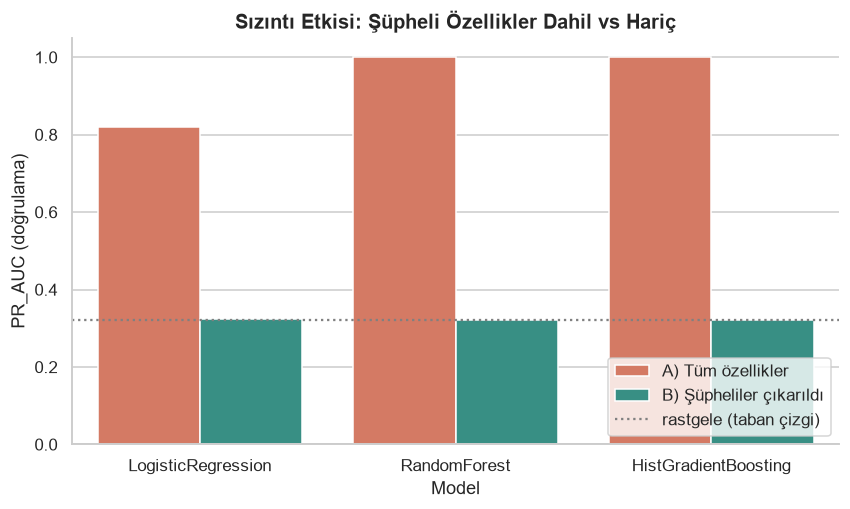

Senaryo,A) Tüm özellikler,B) Şüpheliler çıkarıldı
Model,,
HistGradientBoosting,1.0000,0.3212
LogisticRegression,0.8202,0.3233
RandomForest,1.0000,0.3217


In [5]:
# Senaryo karşılaştırması: hızlı bir CV ile (3 model) iki özellik kümesini kıyasla
if cikarilacak and len(TUM_OZELLIKLER) - len(cikarilacak) >= 3:
    kalanlar = [c for c in TUM_OZELLIKLER if c not in cikarilacak]
    satirlar = []
    for ad in ["LogisticRegression", "RandomForest", "HistGradientBoosting"]:
        for etiket, cols in [("A) Tüm özellikler", TUM_OZELLIKLER), ("B) Şüpheliler çıkarıldı", kalanlar)]:
            r = cv_degerlendir(yeni_model(ad), X_train[cols], y_train, "class_weight", n_splits=3)
            satirlar.append({"Model": ad, "Senaryo": etiket, "PR_AUC (doğrulama)": r["val_ap"]})
    sen = pd.DataFrame(satirlar)
    plt.figure(figsize=(9, 4.8))
    sns.barplot(data=sen, x="Model", y="PR_AUC (doğrulama)", hue="Senaryo", palette=["#e76f51", "#2a9d8f"])
    plt.axhline(fraud_orani, color="gray", ls=":", label="rastgele (taban çizgi)")
    plt.ylim(0, 1.05); plt.legend(loc="lower right"); plt.title("Sızıntı Etkisi: Şüpheli Özellikler Dahil vs Hariç")
    plt.show()
    display(sen.pivot(index="Model", columns="Senaryo", values="PR_AUC (doğrulama)"))
else:
    print("Karşılaştırılacak şüpheli özellik yok.")

In [6]:
# Hangi özellik kümesiyle devam ediyoruz?
if OZELLIK_SENARYOSU == "otomatik":
    SENARYO = "supheli_cikar" if (cikarilacak and len(TUM_OZELLIKLER) - len(cikarilacak) >= 3) else "tum"
else:
    SENARYO = OZELLIK_SENARYOSU

OZELLIKLER = [c for c in TUM_OZELLIKLER if c not in cikarilacak] if SENARYO == "supheli_cikar" else TUM_OZELLIKLER
X_train, X_test = X_train[OZELLIKLER], X_test[OZELLIKLER]
print(f"▶ Devam eden senaryo: '{SENARYO}'  →  {len(OZELLIKLER)} özellik")
if SENARYO == "supheli_cikar":
    print("  (Şüpheli özellikler çıkarıldı. Hepsini tutmak için ayarlarda OZELLIK_SENARYOSU = 'tum' yap.)")
elif cikarilacak:
    print("  ⚠️ DİKKAT: Şüpheli özellikler tutuluyor; skorlar abartılı olabilir (yukarıdaki A/B grafiğine bak).")
    print("     Genelleşebilir/dürüst skor için ayarlarda OZELLIK_SENARYOSU = 'supheli_cikar' yap ve tekrar çalıştır.")

# Lazy yarış için eğitim içinden küçük bir doğrulama parçası ayır (test'e DOKUNMUYORUZ)
X_tr, X_va, y_tr, y_va = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=RS)
if len(X_tr) > LAZY_SAMPLE:
    X_tr, _, y_tr, _ = train_test_split(X_tr, y_tr, train_size=LAZY_SAMPLE, stratify=y_tr, random_state=RS)
print(f"Lazy yarış: eğitim {X_tr.shape[0]:,} satır | doğrulama {X_va.shape[0]:,} satır")

▶ Devam eden senaryo: 'tum'  →  20 özellik
  ⚠️ DİKKAT: Şüpheli özellikler tutuluyor; skorlar abartılı olabilir (yukarıdaki A/B grafiğine bak).
     Genelleşebilir/dürüst skor için ayarlarda OZELLIK_SENARYOSU = 'supheli_cikar' yap ve tekrar çalıştır.
Lazy yarış: eğitim 20,000 satır | doğrulama 10,000 satır


## 4. 🏁 "Lazy" Model Yarışı (20+ model, varsayılan ayarlarla)

Hiçbir ayar yapmadan **onlarca modeli aynı veride** yarıştırıp hangi aile işe yarıyor diye bakıyoruz (LazyPredict mantığı).
Tabloda şunlar var:
- **PR_AUC (doğrulama):** asıl başarı ölçüsü
- **PR_AUC (eğitim)** ve **Fark (gap):** eğitimdeki skor doğrulamadan çok yüksekse model **ezber yapıyor (overfit)**
- **F1 / Recall / Precision:** modelin varsayılan eşiğindeki (0.5) değerleri
- **Süre:** eğitim süresi

Çubuk grafikte **kırmızı = overfit şüphesi** (gap > `GAP_ESIGI`).

In [7]:
from sklearn.linear_model import RidgeClassifier, SGDClassifier, Perceptron
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier, BaggingClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier

def lazy_modeller():
    cw = "balanced"
    d = {
        "Dummy (taban)": DummyClassifier(strategy="prior"),
        "LogisticRegression": LogisticRegression(max_iter=2000, class_weight=cw),
        "RidgeClassifier": RidgeClassifier(class_weight=cw),
        "SGDClassifier": SGDClassifier(loss="log_loss", class_weight=cw, random_state=RS),
        "Perceptron": Perceptron(class_weight=cw, random_state=RS),
        "LinearSVC": LinearSVC(class_weight=cw, max_iter=5000, random_state=RS),
        "SVC (RBF)": SVC(class_weight=cw, random_state=RS),
        "KNN": KNeighborsClassifier(),
        "GaussianNB": GaussianNB(),
        "BernoulliNB": BernoulliNB(),
        "LDA": LinearDiscriminantAnalysis(),
        "QDA": QuadraticDiscriminantAnalysis(),
        "DecisionTree": DecisionTreeClassifier(class_weight=cw, random_state=RS),
        "ExtraTree": ExtraTreeClassifier(class_weight=cw, random_state=RS),
        "RandomForest": RandomForestClassifier(n_estimators=200, class_weight=cw, n_jobs=N_JOBS, random_state=RS),
        "ExtraTrees": ExtraTreesClassifier(n_estimators=200, class_weight=cw, n_jobs=N_JOBS, random_state=RS),
        "Bagging": BaggingClassifier(n_estimators=50, n_jobs=N_JOBS, random_state=RS),
        "AdaBoost": AdaBoostClassifier(random_state=RS),
        "GradientBoosting": GradientBoostingClassifier(random_state=RS),
        "HistGradientBoosting": HistGradientBoostingClassifier(class_weight=cw, random_state=RS),
        "MLP (sinir ağı)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=RS),
    }
    if XGB_OK:
        d["XGBoost"] = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=5, eval_metric="logloss", tree_method="hist",
                                     scale_pos_weight=float((y_tr == 0).sum() / max((y_tr == 1).sum(), 1)),
                                     n_jobs=N_JOBS, random_state=RS, verbosity=0)
    if LGBM_OK:
        d["LightGBM"] = LGBMClassifier(n_estimators=300, learning_rate=0.1, class_weight=cw, n_jobs=N_JOBS, random_state=RS, verbose=-1)
    return d

sonuc = []
for ad, m in lazy_modeller().items():
    t0 = time.time()
    try:
        m.fit(X_tr, y_tr)
        s_va, s_tr = skor(m, X_va), skor(m, X_tr)
        yh = m.predict(X_va)
        sonuc.append({"Model": ad,
                      "PR_AUC (doğrulama)": average_precision_score(y_va, s_va),
                      "PR_AUC (eğitim)": average_precision_score(y_tr, s_tr),
                      "ROC_AUC": roc_auc_score(y_va, s_va),
                      "F1": f1_score(y_va, yh), "Recall": recall_score(y_va, yh),
                      "Precision": precision_score(y_va, yh, zero_division=0),
                      "Accuracy": accuracy_score(y_va, yh), "Süre (sn)": time.time() - t0})
    except Exception as e:
        print(f"⚠️ {ad} atlandı: {str(e)[:70]}")

lazy = pd.DataFrame(sonuc)
lazy["Fark (gap)"] = lazy["PR_AUC (eğitim)"] - lazy["PR_AUC (doğrulama)"]
lazy = lazy.sort_values("PR_AUC (doğrulama)", ascending=False).reset_index(drop=True)
lazy.index += 1
display(lazy)

,Model,PR_AUC (doğrulama),PR_AUC (eğitim),ROC_AUC,F1,Recall,Precision,Accuracy,Süre (sn),Fark (gap)
1,Bagging,1.0000,1.0000,1.0000,0.9998,0.9997,1.0000,0.9999,7.0780,0.0000
2,RandomForest,1.0000,1.0000,1.0000,0.9998,0.9997,1.0000,0.9999,2.1292,0.0000
3,HistGradientBoosting,1.0000,1.0000,1.0000,0.9978,0.9975,0.9981,0.9986,2.2293,0.0000
4,LightGBM,1.0000,1.0000,1.0000,0.9980,0.9984,0.9975,0.9987,0.6200,0.0000
5,XGBoost,1.0000,1.0000,1.0000,0.9991,0.9994,0.9988,0.9994,2.3641,0.0000
6,MLP (sinir ağı),0.9998,1.0000,0.9999,0.9922,0.9950,0.9895,0.9950,8.8808,0.0002
7,AdaBoost,0.9998,1.0000,0.9998,0.9998,0.9997,1.0000,0.9999,2.7357,0.0002
8,GradientBoosting,0.9998,1.0000,0.9998,0.9998,0.9997,1.0000,0.9999,6.2079,0.0002
9,DecisionTree,0.9998,1.0000,0.9998,0.9998,0.9997,1.0000,0.9999,0.1465,0.0002
10,ExtraTrees,0.9996,1.0000,0.9998,0.9860,0.9745,0.9978,0.9911,2.0262,0.0004


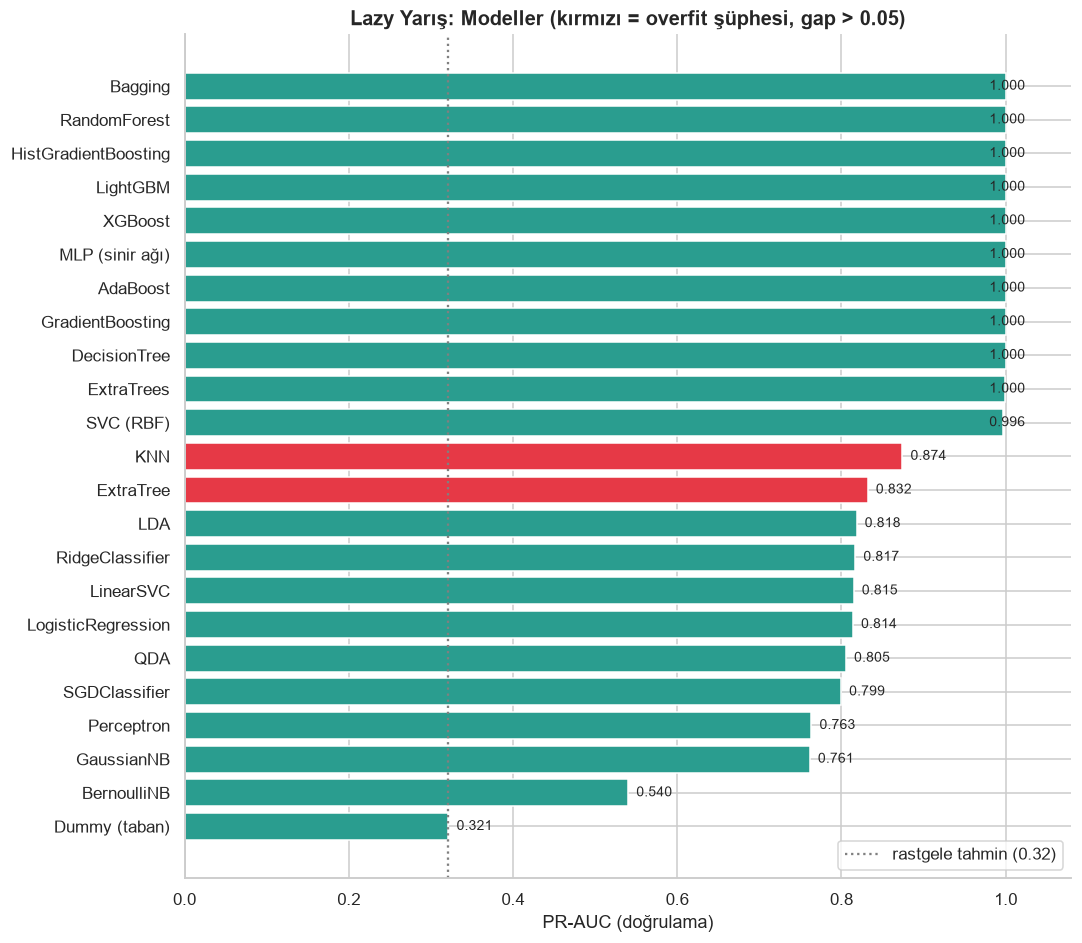

Derin incelemeye alınan adaylar: ['RandomForest', 'HistGradientBoosting', 'LogisticRegression', 'XGBoost', 'LightGBM']


In [8]:
# Görselleştirme: doğrulama PR-AUC (renk = overfit durumu)
renkler = ["#e63946" if g > GAP_ESIGI else "#2a9d8f" for g in lazy["Fark (gap)"]]
fig, ax = plt.subplots(figsize=(10, max(5, len(lazy) * 0.38)))
ax.barh(lazy["Model"][::-1], lazy["PR_AUC (doğrulama)"][::-1], color=renkler[::-1])
ax.axvline(fraud_orani, color="gray", ls=":", label=f"rastgele tahmin ({fraud_orani:.2f})")
for i, (v, g) in enumerate(zip(lazy["PR_AUC (doğrulama)"][::-1], lazy["Fark (gap)"][::-1])):
    ax.text(min(v + 0.01, 0.98), i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1.08); ax.set_xlabel("PR-AUC (doğrulama)"); ax.legend(loc="lower right")
ax.set_title("Lazy Yarış: Modeller (kırmızı = overfit şüphesi, gap > %.2f)" % GAP_ESIGI)
plt.tight_layout(); plt.show()

# Final adayları: istenen aileler (Lojistik taban çizgi, Random Forest, boosting) + lazy yarışta overfit'i düşük çıkan en iyi 3 model
ZORUNLU = ["LogisticRegression", "RandomForest", "HistGradientBoosting"] + (["XGBoost"] if XGB_OK else []) + (["LightGBM"] if LGBM_OK else [])
iyi = lazy[(lazy["Fark (gap)"] <= GAP_ESIGI * 2) & (~lazy["Model"].str.contains("Dummy"))]["Model"].head(3).tolist()
ADAYLAR = list(dict.fromkeys([a for a in iyi if a in ZORUNLU] + ZORUNLU))
print("Derin incelemeye alınan adaylar:", ADAYLAR)

## 5. Çapraz Doğrulama ile Adayları Karşılaştırma (StratifiedKFold)

Tek bir bölme şansa bağlı olabilir. Bu yüzden adayları **K-kat çapraz doğrulama** ile değerlendiriyorum.
Her model için **eğitim PR-AUC** ve **doğrulama PR-AUC** ölçülür:

| Durum | Eğitim | Doğrulama | Anlamı |
|---|---|---|---|
| ✅ İyi | yüksek | yüksek, aradaki fark küçük | Genelleştiriyor |
| ⚠️ **Overfit** | çok yüksek | belirgin daha düşük | Ezberliyor |
| ⚠️ **Underfit** | düşük | düşük | Model çok basit / veride sinyal yok |

,Model,Eğitim PR-AUC,Doğrulama PR-AUC,Std (±),Fark (gap),Süre (sn),Teşhis
0,RandomForest,1.0000,1.0000,0.0000,0.0000,11.9811,✅ Dengeli
1,HistGradientBoosting,1.0000,1.0000,0.0000,0.0000,10.9228,✅ Dengeli
2,LightGBM,1.0000,1.0000,0.0000,0.0000,2.3755,✅ Dengeli
3,XGBoost,1.0000,1.0000,0.0000,0.0000,2.8813,✅ Dengeli
4,LogisticRegression,0.8206,0.8202,0.0042,0.0005,0.9733,✅ Dengeli


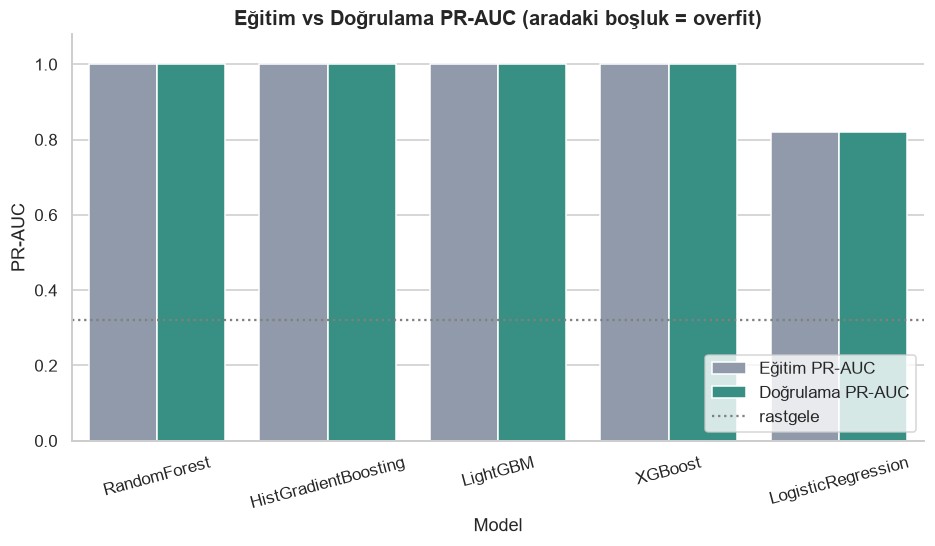


🏆 CV'ye göre en iyi aday: RandomForest  (doğrulama PR-AUC = 1.0000)


In [9]:
cv_sonuc, oof_tablo = [], {}
for ad in ADAYLAR:
    t0 = time.time()
    r = cv_degerlendir(yeni_model(ad), X_train, y_train, "class_weight")
    oof_tablo[ad] = r["oof"]
    cv_sonuc.append({"Model": ad, "Eğitim PR-AUC": r["train_ap"], "Doğrulama PR-AUC": r["val_ap"],
                     "Std (±)": r["val_std"], "Fark (gap)": r["gap"], "Süre (sn)": time.time() - t0})
cv_df = pd.DataFrame(cv_sonuc).sort_values("Doğrulama PR-AUC", ascending=False).reset_index(drop=True)

def teshis(satir):
    if satir["Fark (gap)"] > GAP_ESIGI: return "⚠️ Overfit"
    if satir["Doğrulama PR-AUC"] < fraud_orani + 0.10: return "⚠️ Underfit / zayıf sinyal"
    return "✅ Dengeli"
cv_df["Teşhis"] = cv_df.apply(teshis, axis=1)
display(cv_df)

m = cv_df.melt(id_vars="Model", value_vars=["Eğitim PR-AUC", "Doğrulama PR-AUC"], var_name="Küme", value_name="PR-AUC")
plt.figure(figsize=(10, 4.8))
sns.barplot(data=m, x="Model", y="PR-AUC", hue="Küme", palette=["#8d99ae", "#2a9d8f"])
plt.axhline(fraud_orani, color="gray", ls=":", label="rastgele")
plt.ylim(0, 1.08); plt.legend(loc="lower right")
plt.title("Eğitim vs Doğrulama PR-AUC (aradaki boşluk = overfit)"); plt.xticks(rotation=15)
plt.show()

EN_IYI_AD = cv_df.iloc[0]["Model"]
print(f"\n🏆 CV'ye göre en iyi aday: {EN_IYI_AD}  (doğrulama PR-AUC = {cv_df.iloc[0]['Doğrulama PR-AUC']:.4f})")

## 6. Dengesizlik Stratejilerini Karşılaştırma ⚖️

Seçilen en iyi model için dört stratejiyi çapraz doğrulama içinde deniyorum.
**Dengeleme sadece eğitim katına uygulanır**; doğrulama katı orijinal dağılımda kalır (gerçek hayatta test de böyle olacak).
Ayrıca **hangi stratejinin eşik 0.5'te daha iyi Recall verdiğine** bakıyorum.

,Strateji,Doğrulama PR-AUC,Eğitim PR-AUC,Fark (gap),Recall@0.5,Precision@0.5
0,agirlik_yok,1.0000,1.0000,0.0000,0.9999,1.0000
1,class_weight,1.0000,1.0000,0.0000,1.0000,1.0000
2,undersample,1.0000,1.0000,0.0000,1.0000,0.9998


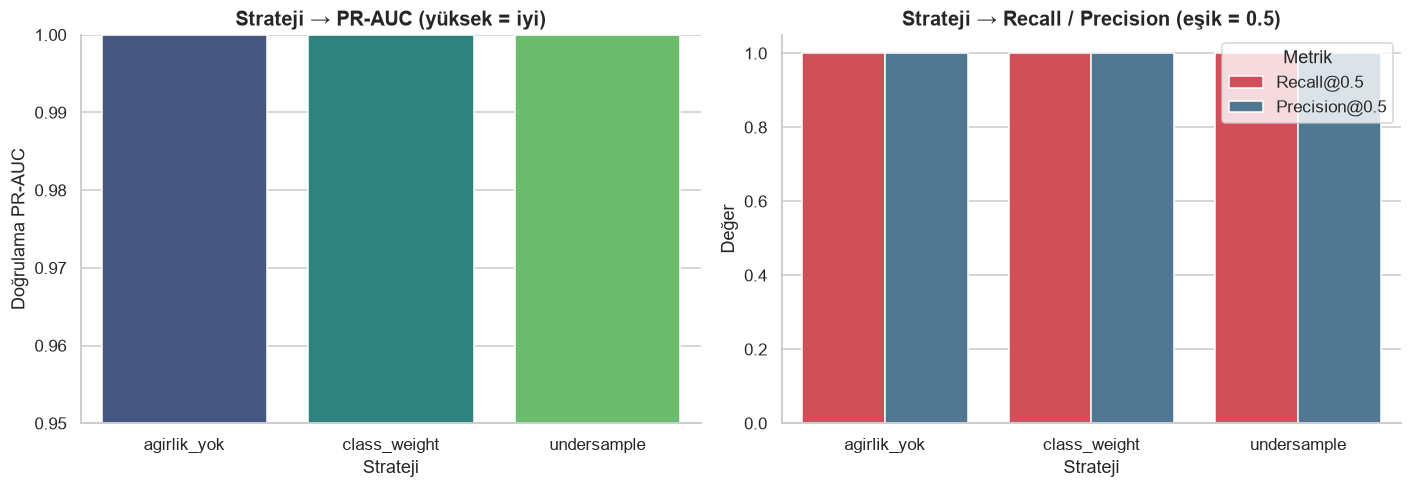

▶ Seçilen strateji: class_weight  (farklar çok küçükse en basit/ucuz olan tercih edilir)


In [10]:
satir = []; oof_strateji = {}
for st in STRATEJILER:
    r = cv_degerlendir(yeni_model(EN_IYI_AD), X_train, y_train, st)
    oof_strateji[st] = r["oof"]
    # 0.5 eşiğinde Recall/Precision: undersample/SMOTE/class_weight olasılıkları kaydırdığı için fark görünür
    yh = (r["oof"] >= 0.5).astype(int)
    satir.append({"Strateji": st, "Doğrulama PR-AUC": r["val_ap"], "Eğitim PR-AUC": r["train_ap"], "Fark (gap)": r["gap"],
                  "Recall@0.5": recall_score(y_train, yh), "Precision@0.5": precision_score(y_train, yh, zero_division=0)})
st_df = pd.DataFrame(satir).sort_values("Doğrulama PR-AUC", ascending=False).reset_index(drop=True)
display(st_df)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sns.barplot(data=st_df, x="Strateji", y="Doğrulama PR-AUC", palette="viridis", ax=ax[0])
ax[0].set_ylim(max(0, st_df["Doğrulama PR-AUC"].min() - 0.05), min(1.0, st_df["Doğrulama PR-AUC"].max() + 0.03))
ax[0].set_title("Strateji → PR-AUC (yüksek = iyi)")
mm = st_df.melt(id_vars="Strateji", value_vars=["Recall@0.5", "Precision@0.5"], var_name="Metrik", value_name="Değer")
sns.barplot(data=mm, x="Strateji", y="Değer", hue="Metrik", palette=["#e63946", "#457b9d"], ax=ax[1])
ax[1].set_title("Strateji → Recall / Precision (eşik = 0.5)"); ax[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

# Strateji kararı: PR-AUC en yüksek olan; fark çok küçükse (<0.005) en basit olanı (class_weight) tercih et
en_ust = st_df.iloc[0]
STRATEJI = en_ust["Strateji"]
if "class_weight" in st_df["Strateji"].values:
    cw_ap = st_df.loc[st_df["Strateji"] == "class_weight", "Doğrulama PR-AUC"].iloc[0]
    if en_ust["Doğrulama PR-AUC"] - cw_ap < 0.005:
        STRATEJI = "class_weight"
print(f"▶ Seçilen strateji: {STRATEJI}  (farklar çok küçükse en basit/ucuz olan tercih edilir)")

## 7. Isolation Forest — Denetimsiz Karşılaştırma 🌲

**Isolation Forest etiket kullanmaz**: "Diğerlerinden kolay izole edilen = anormal" mantığıyla çalışır.
Fraud'u etiketsiz yakalayabilir mi diye bakıyoruz. Genelde etiketli modellerden **daha zayıftır**; çünkü fraud her zaman "uç değer" gibi görünmez,
bazen normal işleme çok benzer. Bu karşılaştırma **etiketlerin değerini** gösterir.

,Model,PR_AUC,ROC_AUC
0,Isolation Forest (denetimsiz),0.3948,0.5929
1,RandomForest (etiketli),1.0000,1.0000
2,Rastgele,0.3213,0.5000


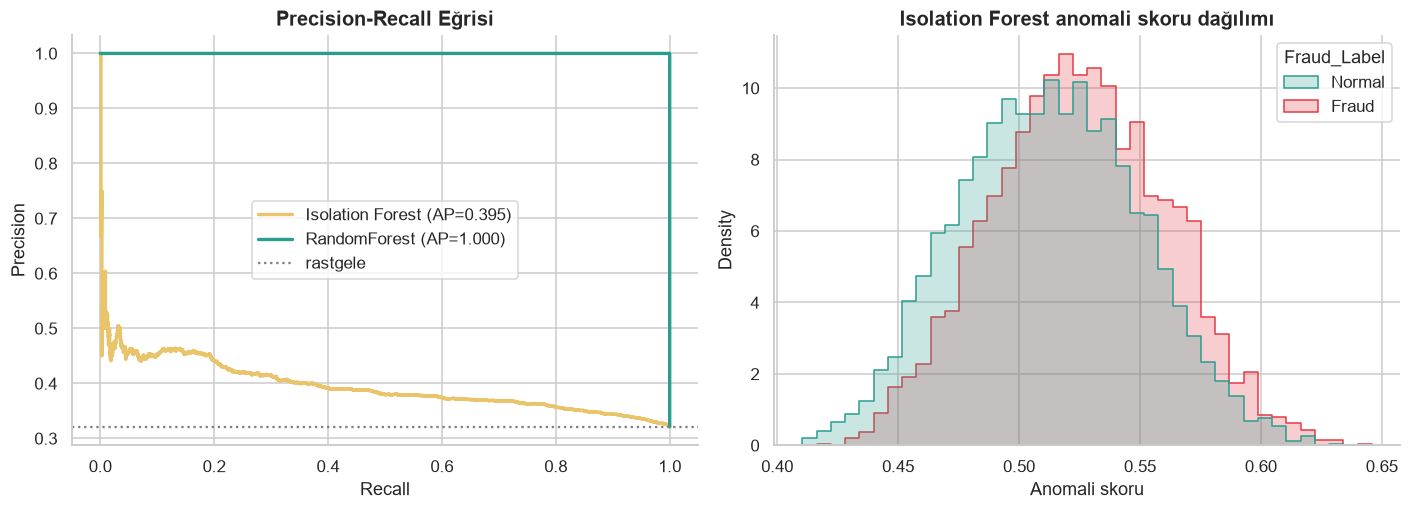

In [11]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=300, contamination=float(min(fraud_orani, 0.5)), random_state=RS, n_jobs=N_JOBS)
iso.fit(X_tr)                              # y_tr KULLANILMIYOR (denetimsiz)
iso_skor = -iso.score_samples(X_va)        # yüksek = daha anormal = daha olası fraud
iso_ap, iso_roc = average_precision_score(y_va, iso_skor), roc_auc_score(y_va, iso_skor)

# Aynı doğrulama parçasında etiketli en iyi modelle yan yana koy
mm_ = clone(yeni_model(EN_IYI_AD)); mm_ = ayarla_agirlik(mm_, y_tr); mm_.fit(X_tr, y_tr)
sup_skor = skor(mm_, X_va)
sup_ap, sup_roc = average_precision_score(y_va, sup_skor), roc_auc_score(y_va, sup_skor)

karsi = pd.DataFrame({"Model": ["Isolation Forest (denetimsiz)", f"{EN_IYI_AD} (etiketli)", "Rastgele"],
                      "PR_AUC": [iso_ap, sup_ap, y_va.mean()], "ROC_AUC": [iso_roc, sup_roc, 0.5]})
display(karsi)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for ad_, s_, c_ in [("Isolation Forest", iso_skor, "#e9c46a"), (EN_IYI_AD, sup_skor, "#2a9d8f")]:
    p_, r_, _ = precision_recall_curve(y_va, s_)
    ax[0].plot(r_, p_, color=c_, lw=2.2, label=f"{ad_} (AP={average_precision_score(y_va, s_):.3f})")
ax[0].axhline(y_va.mean(), color="gray", ls=":", label="rastgele")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision-Recall Eğrisi"); ax[0].legend()
sns.histplot(x=iso_skor, hue=y_va.map({0: "Normal", 1: "Fraud"}), bins=40, stat="density", common_norm=False,
             element="step", palette={"Normal": PAL[0], "Fraud": PAL[1]}, ax=ax[1])
ax[1].set_title("Isolation Forest anomali skoru dağılımı"); ax[1].set_xlabel("Anomali skoru")
plt.tight_layout(); plt.show()

## 8. Hiperparametre Ayarı (overfit'e karşı kısıtlı arama)

En iyi model ailesi için **rastgele arama** yapıyorum. Arama alanı bilerek **karmaşıklığı sınırlayan** değerler içerir
(derinlik, minimum yaprak örneği, düzenlileştirme). Seçim kuralı:

> Önce **gap ≤ `GAP_ESIGI`** olan kombinasyonlar arasından doğrulama PR-AUC'si en yüksek olanı al.
> Hiçbiri yoksa **gap'i en küçük** olanı al. (Yani "en yüksek skor" değil, "en güvenilir skor" peşindeyiz.)

🔧 Ayarlanan model: RandomForest | 12 kombinasyon denendi
✅ Seçilen parametreler: {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 8}
   Doğrulama PR-AUC=1.0000 | Eğitim PR-AUC=1.0000 | gap=0.0000


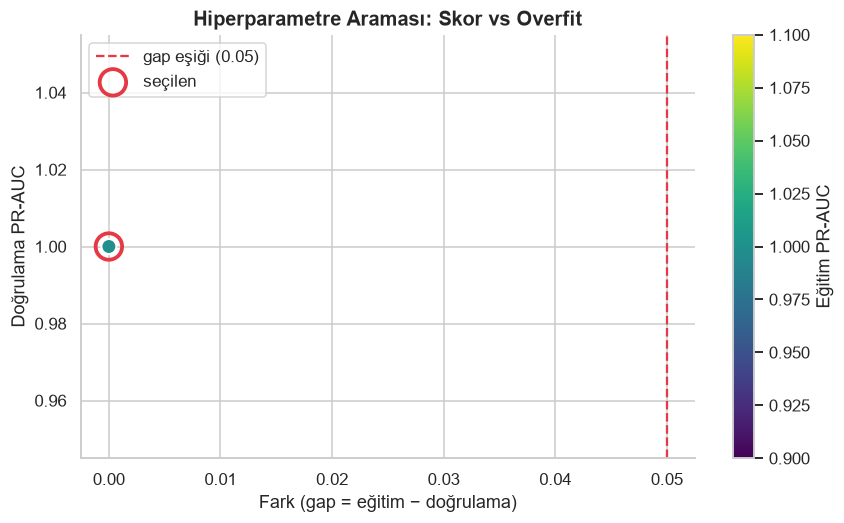

In [12]:
IZGARALAR = {
    "RandomForest": {"n_estimators": [200, 300, 500], "max_depth": [4, 6, 8, 12, 16], "min_samples_leaf": [1, 3, 5, 10, 20],
                     "max_features": ["sqrt", 0.5]},
    "HistGradientBoosting": {"learning_rate": [0.03, 0.05, 0.1], "max_depth": [3, 4, 6, None], "max_leaf_nodes": [15, 31, 63],
                             "min_samples_leaf": [20, 50, 100], "l2_regularization": [0.0, 0.1, 1.0, 10.0], "max_iter": [100, 200, 300]},
    "LogisticRegression": {"C": [0.01, 0.1, 1, 10, 100], "max_iter": [3000]},
    "XGBoost": {"n_estimators": [150, 300, 500], "max_depth": [3, 4, 5, 6], "learning_rate": [0.03, 0.05, 0.1],
                "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.7, 0.85, 1.0], "reg_lambda": [1, 5, 10],
                "min_child_weight": [1, 5, 10]},
    "LightGBM": {"n_estimators": [150, 300, 500], "num_leaves": [15, 31, 63], "learning_rate": [0.03, 0.05, 0.1],
                 "min_child_samples": [20, 50, 100], "reg_lambda": [0, 1, 5, 10], "subsample": [0.7, 0.85, 1.0],
                 "colsample_bytree": [0.7, 0.85, 1.0]},
}

# Izgarası olan en iyi modeli ayarla
sirali = [a for a in cv_df["Model"] if a in IZGARALAR]
AYAR_AD = sirali[0] if sirali else None
if AYAR_AD is None:
    print("Bu aday için arama ızgarası tanımlı değil; varsayılan ayarlarla devam ediliyor.")
    EN_IYI_PARAM, ayar_df = {}, None
    ILK_AD = EN_IYI_AD
else:
    deneme = []
    ızgara_boyutu = int(np.prod([len(v) for v in IZGARALAR[AYAR_AD].values()]))
    for i, p in enumerate(ParameterSampler(IZGARALAR[AYAR_AD], n_iter=min(N_ITER, ızgara_boyutu), random_state=RS)):
        m_ = yeni_model(AYAR_AD).set_params(**p)
        r = cv_degerlendir(m_, X_train, y_train, STRATEJI)
        deneme.append({"param": p, "Doğrulama PR-AUC": r["val_ap"], "Eğitim PR-AUC": r["train_ap"], "Fark (gap)": r["gap"]})
    ayar_df = pd.DataFrame(deneme)
    uygun = ayar_df[ayar_df["Fark (gap)"] <= GAP_ESIGI]
    sec = (uygun.sort_values("Doğrulama PR-AUC", ascending=False).iloc[0] if len(uygun)
           else ayar_df.sort_values("Fark (gap)").iloc[0])
    EN_IYI_PARAM = sec["param"]
    ILK_AD = AYAR_AD
    print(f"🔧 Ayarlanan model: {AYAR_AD} | {len(ayar_df)} kombinasyon denendi")
    print(f"✅ Seçilen parametreler: {EN_IYI_PARAM}")
    print(f"   Doğrulama PR-AUC={sec['Doğrulama PR-AUC']:.4f} | Eğitim PR-AUC={sec['Eğitim PR-AUC']:.4f} | gap={sec['Fark (gap)']:.4f}")

    plt.figure(figsize=(9, 5))
    sc = plt.scatter(ayar_df["Fark (gap)"], ayar_df["Doğrulama PR-AUC"], c=ayar_df["Eğitim PR-AUC"], cmap="viridis", s=90, edgecolor="white")
    plt.axvline(GAP_ESIGI, color="#e63946", ls="--", label=f"gap eşiği ({GAP_ESIGI})")
    plt.scatter([sec["Fark (gap)"]], [sec["Doğrulama PR-AUC"]], s=300, facecolors="none", edgecolors="#e63946", linewidths=2.5, label="seçilen")
    plt.colorbar(sc, label="Eğitim PR-AUC"); plt.xlabel("Fark (gap = eğitim − doğrulama)"); plt.ylabel("Doğrulama PR-AUC")
    plt.title("Hiperparametre Araması: Skor vs Overfit"); plt.legend(); plt.show()

def final_model_olustur():
    m = yeni_model(ILK_AD)
    if EN_IYI_PARAM:
        m.set_params(**EN_IYI_PARAM)
    return m

## 9. Overfit / Underfit Teşhisi 🔬

İki klasik grafik:
- **Öğrenme eğrisi (learning curve):** Eğitim verisi arttıkça skorlar nasıl değişiyor?
  - İki eğri **birbirine yakın ve yüksek** → ✅ iyi
  - Eğitim çok yüksek, doğrulama düşük, **aralarında boşluk** → ⚠️ overfit (daha fazla veri veya daha basit model)
  - İki eğri de **düşük** → ⚠️ underfit (daha güçlü model veya daha iyi özellik)
- **Doğrulama eğrisi (validation curve):** Model karmaşıklığı (ağaç derinliği) artınca ne oluyor? Doğrulama skoru zirve yapıp düşmeye başladığı yer = overfit'in başladığı yer.

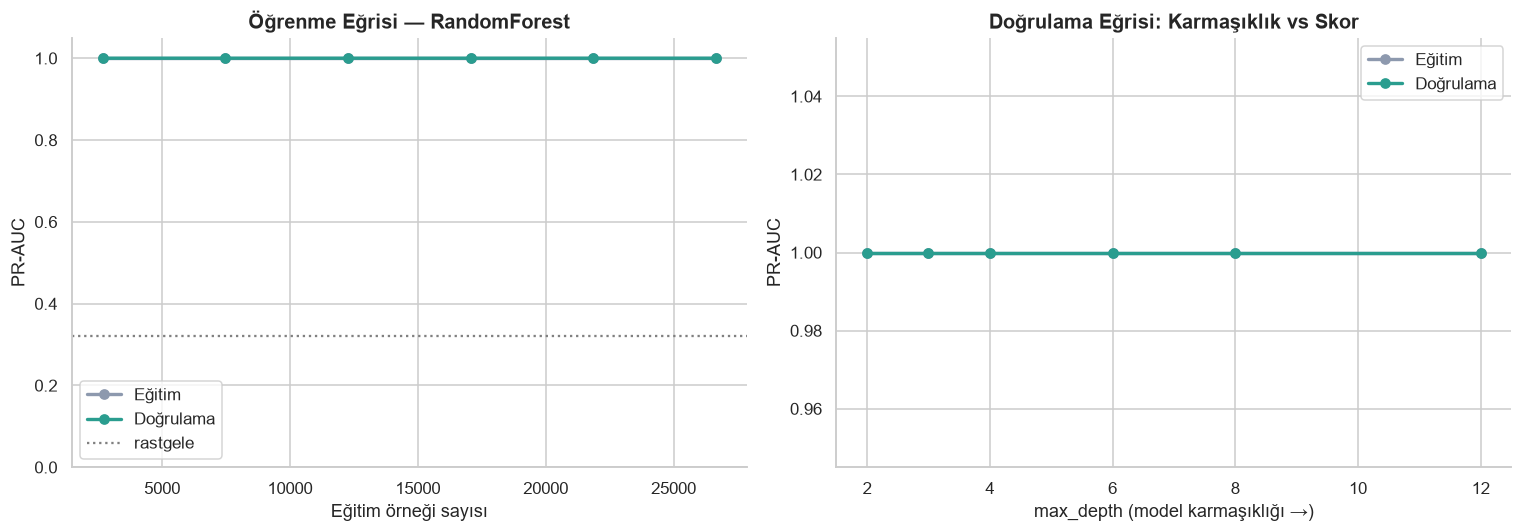

Tüm veriyle: eğitim=1.0000 | doğrulama=1.0000 | gap=0.0000
✅ Eğriler birbirine yakın ve yüksek: model genelleştiriyor görünüyor.


In [13]:
skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
LC_model = ayarla_agirlik(final_model_olustur(), y_train) if STRATEJI == "class_weight" else final_model_olustur()

sizes, trs, vas = learning_curve(LC_model, X_train, y_train, cv=skf3, scoring="average_precision",
                                 train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=N_JOBS, random_state=RS)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for arr, ad_, c_ in [(trs, "Eğitim", "#8d99ae"), (vas, "Doğrulama", "#2a9d8f")]:
    ax[0].plot(sizes, arr.mean(1), "o-", color=c_, lw=2.2, label=ad_)
    ax[0].fill_between(sizes, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), color=c_, alpha=0.18)
ax[0].axhline(fraud_orani, color="gray", ls=":", label="rastgele")
ax[0].set_xlabel("Eğitim örneği sayısı"); ax[0].set_ylabel("PR-AUC"); ax[0].set_title(f"Öğrenme Eğrisi — {ILK_AD}"); ax[0].legend()
ax[0].set_ylim(0, 1.05)

# Doğrulama eğrisi: karmaşıklık parametresi (max_depth) — varsa
param_adi = "max_depth" if "max_depth" in LC_model.get_params() else None
if param_adi:
    degerler = [2, 3, 4, 6, 8, 12]
    ptr, pva = validation_curve(LC_model, X_train, y_train, param_name=param_adi, param_range=degerler,
                                cv=skf3, scoring="average_precision", n_jobs=N_JOBS)
    ax[1].plot(degerler, ptr.mean(1), "o-", color="#8d99ae", lw=2.2, label="Eğitim")
    ax[1].plot(degerler, pva.mean(1), "o-", color="#2a9d8f", lw=2.2, label="Doğrulama")
    ax[1].fill_between(degerler, pva.mean(1) - pva.std(1), pva.mean(1) + pva.std(1), color="#2a9d8f", alpha=0.18)
    ax[1].set_xlabel("max_depth (model karmaşıklığı →)"); ax[1].set_ylabel("PR-AUC"); ax[1].legend()
    ax[1].set_title("Doğrulama Eğrisi: Karmaşıklık vs Skor")
else:
    ax[1].axis("off"); ax[1].text(0.5, 0.5, "Bu modelde max_depth yok\n(doğrulama eğrisi atlandı)", ha="center", va="center")
plt.tight_layout(); plt.show()

son_gap = trs.mean(1)[-1] - vas.mean(1)[-1]
print(f"Tüm veriyle: eğitim={trs.mean(1)[-1]:.4f} | doğrulama={vas.mean(1)[-1]:.4f} | gap={son_gap:.4f}")
if son_gap > GAP_ESIGI:
    print("⚠️ Overfit işareti: Model karmaşıklığını azalt (max_depth↓, min_samples_leaf↑, düzenlileştirme↑) ya da daha fazla veri kullan.")
elif vas.mean(1)[-1] < fraud_orani + 0.10:
    print("⚠️ Underfit işareti: Skorlar düşük. Daha güçlü model / daha iyi özellik gerekir (ya da veride sinyal zayıf).")
else:
    print("✅ Eğriler birbirine yakın ve yüksek: model genelleştiriyor görünüyor.")

## 10. Eşik (Threshold) Seçimi — Precision-Recall Eğrisinden 🎚️

Model her işlem için bir **fraud olasılığı** verir. "Olasılık ≥ eşik ise fraud de" kuralındaki **0.5 genelde yanlış eşiktir**.
Eşiği **test'e bakmadan**, çapraz doğrulamadaki *out-of-fold* tahminlerden (modelin görmediği satırlardaki tahminler) seçiyorum:
- `f1` stratejisi: F1'i maksimum yapan eşik
- `recall` stratejisi: Recall ≥ `HEDEF_RECALL` olan eşikler arasında Precision'ı en yüksek olan

> Bankada "fraud kaçırmak" "yanlış alarmdan" pahalıysa `THRESHOLD_STRATEJISI = "recall"` seçilir.

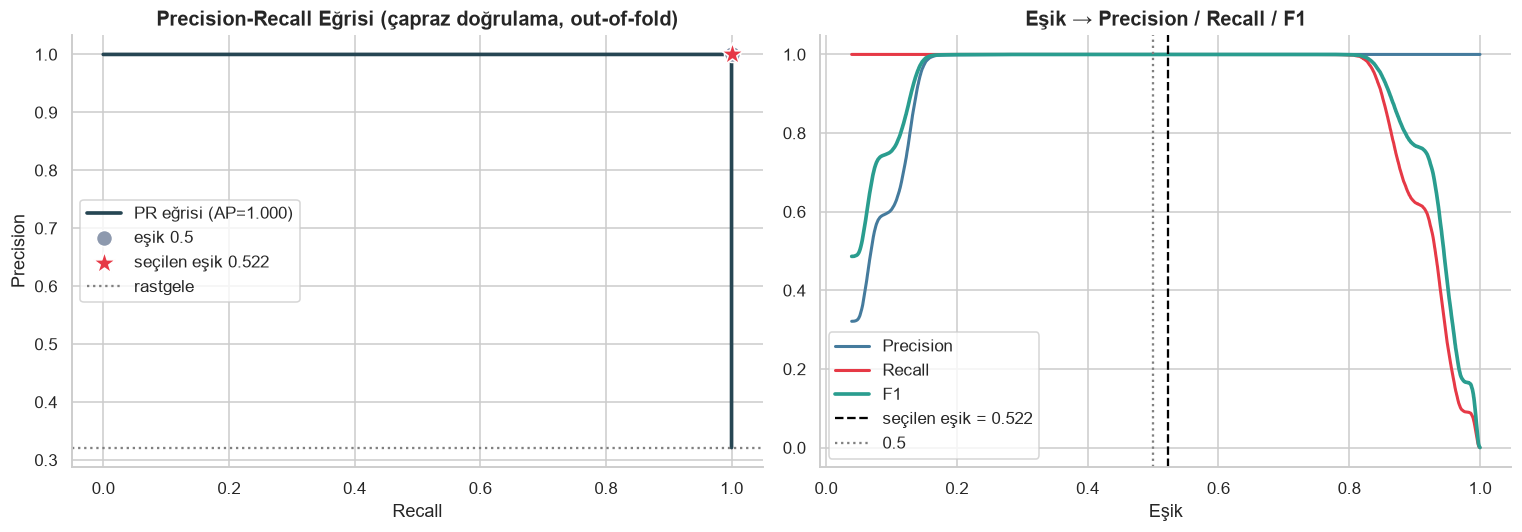

F1-optimal eşik: 0.5223 | Recall≥0.90 eşiği: 0.5223
▶ Kullanılan eşik (f1): 0.5223   (train çapraz doğrulamasından, test'e bakılmadan seçildi)


In [14]:
final_cv = cv_degerlendir(final_model_olustur(), X_train, y_train, STRATEJI)
oof = final_cv["oof"]

p, r, t = precision_recall_curve(y_train, oof)
f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
t_f1 = float(t[f1s.argmax()])
mask = r[:-1] >= HEDEF_RECALL
t_rec = float(t[mask][p[:-1][mask].argmax()]) if mask.any() else t_f1
ESIK = t_f1 if THRESHOLD_STRATEJISI == "f1" else t_rec

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(r, p, color="#264653", lw=2.4, label=f"PR eğrisi (AP={average_precision_score(y_train, oof):.3f})")
for e_, ad_, c_, mk in [(0.5, "eşik 0.5", "#8d99ae", "o"), (ESIK, f"seçilen eşik {ESIK:.3f}", "#e63946", "*")]:
    yh = (oof >= e_).astype(int)
    ax[0].scatter([recall_score(y_train, yh)], [precision_score(y_train, yh, zero_division=0)], s=240 if mk == "*" else 110,
                  color=c_, marker=mk, zorder=5, edgecolor="white", label=ad_)
ax[0].axhline(fraud_orani, color="gray", ls=":", label="rastgele")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision-Recall Eğrisi (çapraz doğrulama, out-of-fold)"); ax[0].legend()

ax[1].plot(t, p[:-1], label="Precision", color="#457b9d", lw=2)
ax[1].plot(t, r[:-1], label="Recall", color="#e63946", lw=2)
ax[1].plot(t, f1s, label="F1", color="#2a9d8f", lw=2.4)
ax[1].axvline(ESIK, color="black", ls="--", label=f"seçilen eşik = {ESIK:.3f}")
ax[1].axvline(0.5, color="gray", ls=":", label="0.5")
ax[1].set_xlabel("Eşik"); ax[1].set_title("Eşik → Precision / Recall / F1"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"F1-optimal eşik: {t_f1:.4f} | Recall≥{HEDEF_RECALL:.2f} eşiği: {t_rec:.4f}")
print(f"▶ Kullanılan eşik ({THRESHOLD_STRATEJISI}): {ESIK:.4f}   (train çapraz doğrulamasından, test'e bakılmadan seçildi)")

## 11. 🧪 Final Test (Tek Seferlik)

Şimdiye kadar **test setine hiç dokunmadık**. Seçilen model + strateji + parametreler + eşik ile:
1. Modeli **tüm train verisiyle** eğit (dengeleme yalnızca train'e)
2. **Test setinde bir kez** değerlendir
3. Karışıklık matrisine bak (eşik 0.5 vs seçilen eşik)

Test skoru, çapraz doğrulama skoruna yakınsa model gerçekten genelleşiyor demektir.

,PR_AUC,ROC_AUC,Precision,Recall,F1,MCC,Bal_Acc
Eşik 0.5,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Seçilen eşik (0.522),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


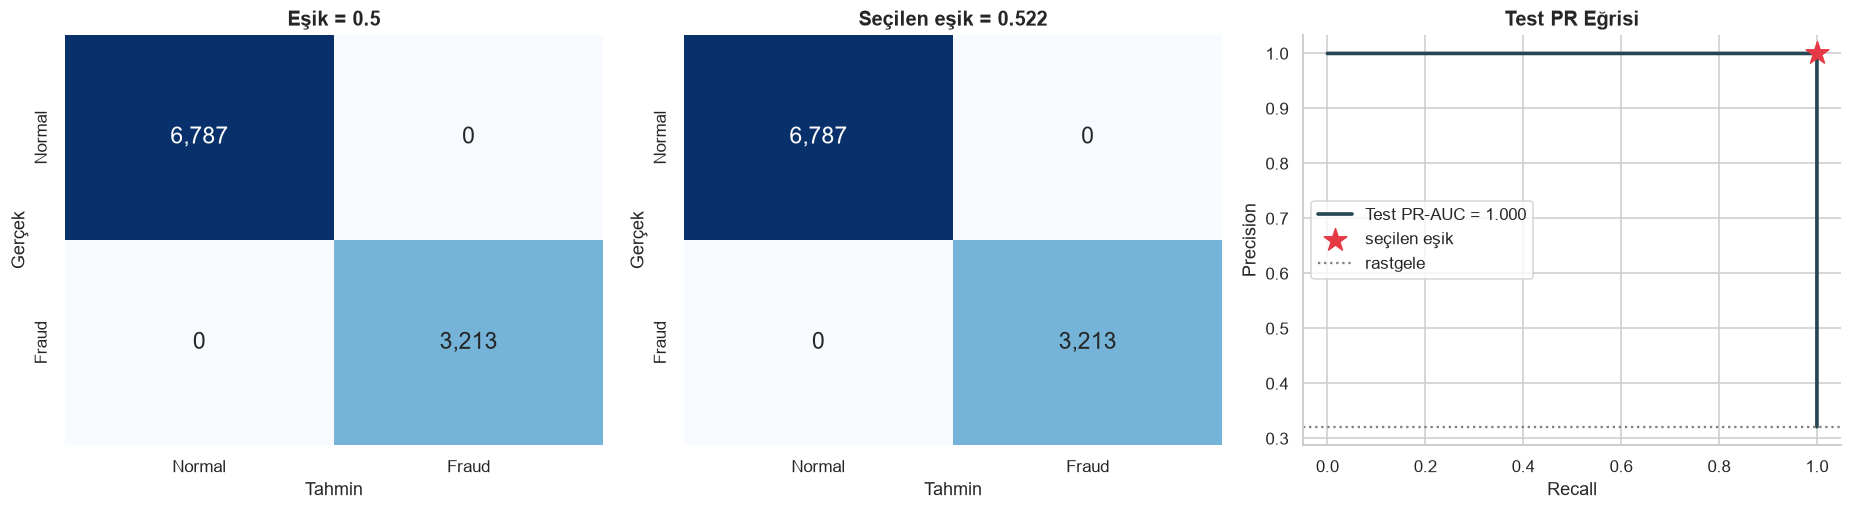

Seçilen eşikte: 3,213 fraud yakalandı, 0 fraud kaçtı, 0 yanlış alarm, 6,787 doğru 'normal'.


In [15]:
final = final_model_olustur()
Xf, yf = X_train, y_train
if STRATEJI == "class_weight":
    final = ayarla_agirlik(final, y_train)
elif STRATEJI == "undersample":
    Xf, yf = rastgele_azalt(X_train, y_train)
elif STRATEJI == "SMOTE":
    Xf, yf = smote_uygula(X_train, y_train)
final.fit(Xf, yf)

s_test = skor(final, X_test)
rap = pd.DataFrame({"Eşik 0.5": metrikler(y_test, s_test, 0.5), f"Seçilen eşik ({ESIK:.3f})": metrikler(y_test, s_test, ESIK)}).T
display(rap)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a_, e_, bas in [(ax[0], 0.5, "Eşik = 0.5"), (ax[1], ESIK, f"Seçilen eşik = {ESIK:.3f}")]:
    cm = confusion_matrix(y_test, (s_test >= e_).astype(int))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=a_, annot_kws={"size": 15},
                xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"])
    a_.set_title(bas); a_.set_xlabel("Tahmin"); a_.set_ylabel("Gerçek")
p_t, r_t, _ = precision_recall_curve(y_test, s_test)
ax[2].plot(r_t, p_t, color="#264653", lw=2.4, label=f"Test PR-AUC = {average_precision_score(y_test, s_test):.3f}")
yh = (s_test >= ESIK).astype(int)
ax[2].scatter([recall_score(y_test, yh)], [precision_score(y_test, yh, zero_division=0)], s=240, marker="*", color="#e63946", zorder=5, label="seçilen eşik")
ax[2].axhline(y_test.mean(), color="gray", ls=":", label="rastgele")
ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].set_title("Test PR Eğrisi"); ax[2].legend()
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, yh).ravel()
print(f"Seçilen eşikte: {tp:,} fraud yakalandı, {fn:,} fraud kaçtı, {fp:,} yanlış alarm, {tn:,} doğru 'normal'.")

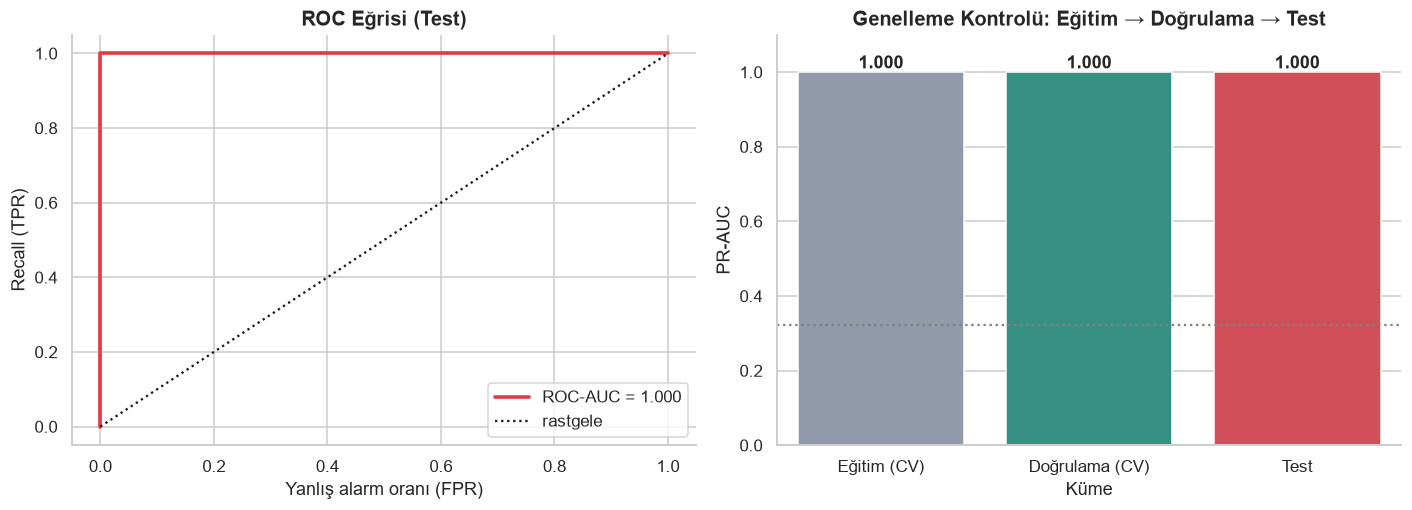

Eğitim–doğrulama gap: 0.0000 | |test − doğrulama|: 0.0000
✅ Eğitim, doğrulama ve test skorları tutarlı: model genelleşiyor görünüyor.
🚨 Skor neredeyse mükemmel. Bu, sızıntı/kural ile üretilmiş bir etikete işaret edebilir (bölüm 3'e dön).


In [16]:
# ROC eğrisi + genelleme kontrolü (test skoru çapraz doğrulama skoruyla uyumlu mu?)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
fpr, tpr, _ = roc_curve(y_test, s_test)
ax[0].plot(fpr, tpr, color="#e63946", lw=2.4, label=f"ROC-AUC = {roc_auc_score(y_test, s_test):.3f}")
ax[0].plot([0, 1], [0, 1], "k:", label="rastgele"); ax[0].set_xlabel("Yanlış alarm oranı (FPR)"); ax[0].set_ylabel("Recall (TPR)")
ax[0].set_title("ROC Eğrisi (Test)"); ax[0].legend()

test_ap = average_precision_score(y_test, s_test)
kar = pd.DataFrame({"Küme": ["Eğitim (CV)", "Doğrulama (CV)", "Test"],
                    "PR-AUC": [final_cv["train_ap"], final_cv["val_ap"], test_ap]})
sns.barplot(data=kar, x="Küme", y="PR-AUC", palette=["#8d99ae", "#2a9d8f", "#e63946"], ax=ax[1])
for i, v in enumerate(kar["PR-AUC"]):
    ax[1].text(i, v + 0.01, f"{v:.3f}", ha="center", fontweight="bold")
ax[1].set_ylim(0, 1.1); ax[1].axhline(fraud_orani, color="gray", ls=":"); ax[1].set_title("Genelleme Kontrolü: Eğitim → Doğrulama → Test")
plt.tight_layout(); plt.show()

fark_test = abs(test_ap - final_cv["val_ap"])
print(f"Eğitim–doğrulama gap: {final_cv['gap']:.4f} | |test − doğrulama|: {fark_test:.4f}")
if final_cv["gap"] > GAP_ESIGI:
    print("⚠️ OVERFIT şüphesi: eğitim skoru doğrulamadan belirgin yüksek.")
elif test_ap < fraud_orani + 0.10:
    print("⚠️ UNDERFIT / zayıf sinyal: model rastgeleden pek iyi değil.")
elif fark_test > 0.03:
    print("⚠️ Test ile doğrulama arasında fark var: veri küçük olabilir ya da bölme şansı etkilemiş olabilir.")
else:
    print("✅ Eğitim, doğrulama ve test skorları tutarlı: model genelleşiyor görünüyor.")
if test_ap > 0.98:
    print("🚨 Skor neredeyse mükemmel. Bu, sızıntı/kural ile üretilmiş bir etikete işaret edebilir (bölüm 3'e dön).")

## 12. Hangi Özellikler Önemli? (Permutation Importance)

Bir özelliğin değerlerini **karıştırınca** modelin PR-AUC'si ne kadar düşüyor? Çok düşüyorsa model o özelliğe güveniyor demektir.
(Açıklama amaçlıdır; model seçiminde kullanılmadı.)

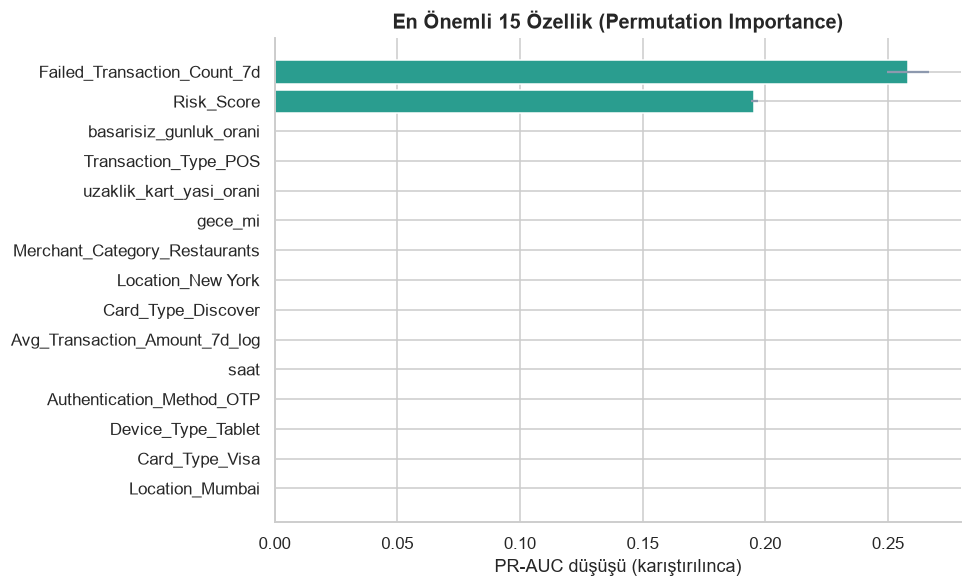

In [17]:
pi = permutation_importance(final, X_test, y_test, scoring="average_precision", n_repeats=5, random_state=RS, n_jobs=N_JOBS)
imp = pd.DataFrame({"Özellik": X_test.columns, "Önem": pi.importances_mean, "Std": pi.importances_std}).sort_values("Önem", ascending=False).head(15)
plt.figure(figsize=(9, 5.5))
plt.barh(imp["Özellik"][::-1], imp["Önem"][::-1], xerr=imp["Std"][::-1], color="#2a9d8f", ecolor="#8d99ae")
plt.xlabel("PR-AUC düşüşü (karıştırılınca)"); plt.title("En Önemli 15 Özellik (Permutation Importance)")
plt.tight_layout(); plt.show()

## 13. Sonuçları Kaydetme ve Özet 💾

In [18]:
import joblib
os.makedirs("model_sonuclari", exist_ok=True)
joblib.dump(final, "model_sonuclari/en_iyi_model.joblib")
lazy.to_csv("model_sonuclari/lazy_yaris.csv", index_label="sira")
son = metrikler(y_test, s_test, ESIK)
with open("model_sonuclari/ozet.json", "w", encoding="utf-8") as f:
    json.dump({"model": ILK_AD, "strateji": STRATEJI, "esik": ESIK, "parametreler": {k: str(v) for k, v in EN_IYI_PARAM.items()},
               "ozellikler": OZELLIKLER, "senaryo": SENARYO, "test": {k: float(v) for k, v in son.items()},
               "cv_val_pr_auc": final_cv["val_ap"], "cv_gap": final_cv["gap"]}, f, ensure_ascii=False, indent=2)

print(f"EN İYİ MODEL: {ILK_AD} | strateji: {STRATEJI} | eşik: {ESIK:.3f} | senaryo: {SENARYO}")
print(f"FINAL TEST → PR-AUC: {son['PR_AUC']:.4f} | Recall: {son['Recall']:.4f} | Precision: {son['Precision']:.4f} | F1: {son['F1']:.4f}")
print("Kaydedildi → model_sonuclari/ (en_iyi_model.joblib, lazy_yaris.csv, ozet.json)")
if SENARYO == "tum" and cikarilacak:
    print("⚠️ UYARI: Bu skorlar şüpheli özellikler (%s) DAHİL hesaplandı; gerçek hayattaki performansı yansıtmayabilir." % ", ".join(supheli[:4]))

EN İYİ MODEL: RandomForest | strateji: class_weight | eşik: 0.522 | senaryo: tum
FINAL TEST → PR-AUC: 1.0000 | Recall: 1.0000 | Precision: 1.0000 | F1: 1.0000
Kaydedildi → model_sonuclari/ (en_iyi_model.joblib, lazy_yaris.csv, ozet.json)
⚠️ UYARI: Bu skorlar şüpheli özellikler (Failed_Transaction_Count_7d, Risk_Score) DAHİL hesaplandı; gerçek hayattaki performansı yansıtmayabilir.


## ✅ Özet — Raporuna Yazacakların
- **Sızıntı kontrolü:** hangi özellikler şüpheliydi, çıkarınca skor ne oldu? (bölüm 3 grafiği)
- **Lazy yarış:** en iyi aileler hangileri, hangileri overfit? (bölüm 4)
- **Dengesizlik:** hangi strateji seçildi, neden? (bölüm 6)
- **Denetimsiz vs denetimli:** Isolation Forest neden geride kaldı? (bölüm 7)
- **Overfit/Underfit:** öğrenme ve doğrulama eğrileri ne dedi? (bölüm 9)
- **Eşik:** neden 0.5 değil? Recall/Precision dengesi ne? (bölüm 10)
- **Test sonucu:** confusion matrix'te kaç fraud yakalandı, kaç yanlış alarm var? (bölüm 11)

**Sonraki adımlar (isteğe bağlı):** olasılık kalibrasyonu, maliyete duyarlı eşik (kaçan fraud tutarı vs yanlış alarm maliyeti), SHAP ile açıklama, zamana göre bölme (gelecekteki işlemlerle test).